# Session 8: Web Scraping in Python

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in ['demo_shop_site.py']:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-08_requests_basics.py`

In [2]:
"""
Session 8 · Example 1: fetching pages with the requests library
---------------------------------------------------------------
Uses the local practice site from demo_shop_site.py, so nothing real is hit.
Run:  python session-08_requests_basics.py
"""
import requests
from demo_shop_site import start_site

BASE = start_site()
HEADERS = {"User-Agent": "DiplomaAI-StudentBot/1.0 (learning project; contact: lecturer@example.edu)"}

# 1. A basic GET request
r = requests.get(BASE + "/", headers=HEADERS, timeout=10)    # ALWAYS set a timeout
print("status:", r.status_code, r.reason, "| ok:", r.ok)
print("content type:", r.headers["Content-Type"], "| encoding:", r.encoding)
print("bytes:", len(r.content), "| first 60 chars of text:", r.text[:60].replace("\n", " "))

# 2. Query parameters: requests builds and encodes the query string
r = requests.get(BASE + "/products", params={"page": 2}, headers=HEADERS, timeout=10)
print("\nfinal URL:", r.url.replace(BASE, "BASE"), "| status:", r.status_code)

# 3. JSON endpoints: .json() parses the body for you
items = requests.get(BASE + "/api/products.json", headers=HEADERS, timeout=10).json()
print("API returned", len(items), "products; first:", items[0])

# 4. Handling errors: check status, catch network exceptions
for path in ["/products?page=9", "/no-such-page"]:
    r = requests.get(BASE + path, headers=HEADERS, timeout=10)
    try:
        r.raise_for_status()                 # raises HTTPError for 4xx/5xx
    except requests.HTTPError as e:
        print(f"HTTPError for {path}: {e.response.status_code}")

try:
    requests.get("http://127.0.0.1:1/", timeout=2)       # nothing listens on port 1
except requests.ConnectionError:
    print("ConnectionError: server unreachable (handled, no crash)")
try:
    requests.get(BASE + "/slow", timeout=0.5)            # this page needs 2 s to answer
except requests.Timeout:
    print("Timeout: the server took too long (handled)")

# 5. A Session reuses the connection and default headers (faster, politer)
with requests.Session() as s:
    s.headers.update(HEADERS)
    sizes = [len(s.get(f"{BASE}/products", params={"page": p}, timeout=10).text) for p in (1, 2, 3)]
print("\npage sizes with one Session:", sizes)

# 6. What the server saw as our identity
print("our User-Agent:", HEADERS["User-Agent"])

status: 200 OK | ok: True
content type: text/html; charset=utf-8 | encoding: utf-8
bytes: 882 | first 60 chars of text: <!doctype html><html><head><meta charset="utf-8"><title>Home

final URL: BASE/products?page=2 | status: 200
API returned 12 products; first: {'id': 1, 'name': 'Wireless Mouse', 'category': 'accessories'}
HTTPError for /products?page=9: 404
HTTPError for /no-such-page: 404
ConnectionError: server unreachable (handled, no crash)


Timeout: the server took too long (handled)

page sizes with one Session: [1734, 1728, 924]
our User-Agent: DiplomaAI-StudentBot/1.0 (learning project; contact: lecturer@example.edu)


## Example: `session-08_bs4_parsing.py`

In [3]:
"""
Session 8 · Example 2: parsing HTML with BeautifulSoup
------------------------------------------------------
Run:  python session-08_bs4_parsing.py
"""
import requests
from bs4 import BeautifulSoup
from demo_shop_site import start_site

BASE = start_site()
html = requests.get(BASE + "/", timeout=10).text
soup = BeautifulSoup(html, "html.parser")        # or "lxml" (faster, needs the lxml package)

# 1. Simple access by tag name
print("title tag:", soup.title, "| text:", soup.title.string)
print("first <h1>:", soup.h1.get_text(), "| its class:", soup.h1["class"])

# 2. find (first match) and find_all (all matches), filtering by attributes
intro = soup.find("p", id="intro")
print("get_text(strip=True):     ", intro.get_text(strip=True))        # pieces glued together!
print("get_text(' ', strip=True):", intro.get_text(" ", strip=True), "| bold word:", intro.b.text)
links = soup.find_all("a")
print("number of links:", len(links))
for a in links:
    print(f"  {a.get_text():<14} -> {a['href']:<28} rel={a.get('rel')}")

# 3. CSS selectors with select / select_one (same syntax as in CSS files)
print("nav links:", [a.text for a in soup.select("nav a")])
print("external links:", [a["href"] for a in soup.select('a[href^="http"]')])
print("footer text:", soup.select_one("footer p").text)

# 4. Turning an HTML table into Python data
table = soup.find("table", id="deals")
rows = []
for tr in table.find_all("tr")[1:]:                       # skip the header row
    cells = [td.get_text(strip=True) for td in tr.find_all("td")]
    rows.append(cells)
headers = [th.text for th in table.find_all("th")]
print("\ntable headers:", headers)
for item, old, new in rows:
    to_int = lambda t: int(t.replace("Rs", "").replace(",", "").strip())
    saving = to_int(old) - to_int(new)
    print(f"  {item:<18} saves Rs {saving:,} ({saving / to_int(old):.0%})")

# 5. Navigating the tree: parent, children, siblings
first_td = soup.find("td")
print("\nfirst <td>:", first_td.text, "| parent tag:", first_td.parent.name,
      "| next sibling:", first_td.find_next_sibling("td").text)
print("children of <nav>:", [c.name for c in soup.nav.children if c.name])

# 6. Product cards: data attributes and nested elements on another page
page = BeautifulSoup(requests.get(BASE + "/products?page=1", timeout=10).text, "html.parser")
for card in page.select("div.product")[:3]:
    print(f"  id={card['data-id']} cat={card['data-category']:<12} "
          f"{card.select_one('.name').get_text(strip=True):<22} {card.select_one('.price').text:<10} "
          f"{card.select_one('.stock').text}")

# 7. Missing elements return None: guard before using them
missing = page.select_one(".discount")
print("missing element ->", missing, "| safe text:", missing.text if missing else "n/a")

title tag: <title>Home</title> | text: Home
first <h1>: TechBazaar Demo | its class: ['site-title']
get_text(strip=True):      Welcome! Today'sdealsare below.
get_text(' ', strip=True): Welcome! Today's deals are below. | bold word: deals
number of links: 6
  Home           -> /                            rel=None
  Products       -> /products?page=1             rel=None
  Jobs           -> /jobs                        rel=None
  All products   -> /products?page=1             rel=None
  Careers        -> /jobs                        rel=None
  Partner site   -> https://example.com/partner  rel=['nofollow']
nav links: ['Home', 'Products', 'Jobs']
external links: ['https://example.com/partner']
footer text: Practice site for scraping lessons. Not a real shop.

table headers: ['Item', 'Old price', 'New price']
  Wireless Mouse     saves Rs 400 (21%)
  Portable SSD 1TB   saves Rs 2,250 (9%)
  32GB USB Drive     saves Rs 250 (18%)

first <td>: Wireless Mouse | parent tag: tr | next sibling:

  id=1 cat=accessories  Wireless Mouse         Rs 1,499   In stock
  id=2 cat=accessories  Mechanical Keyboard    Rs 6,850   In stock
  id=3 cat=accessories  USB-C Hub 7-in-1       Rs. 4,200  Out of stock
missing element -> None | safe text: n/a


## Example: `session-08_rules_and_politeness.py`

In [4]:
"""
Session 8 · Example 3: the rules of scraping - robots.txt, rate limits, caching
-------------------------------------------------------------------------------
Run:  python session-08_rules_and_politeness.py
"""
import time
from urllib import robotparser
import requests
from demo_shop_site import start_site

BASE = start_site()
AGENT = "DiplomaAI-StudentBot/1.0"

# 1. Read robots.txt: the site's instructions for automated visitors
robots_txt = requests.get(BASE + "/robots.txt", timeout=10).text
print("robots.txt says:\n" + robots_txt)
rp = robotparser.RobotFileParser()
rp.parse(robots_txt.splitlines())
for path in ["/products?page=1", "/jobs", "/admin", "/cart"]:
    print(f"  may fetch {path:<18}? {rp.can_fetch(AGENT, BASE + path)}")
delay = rp.crawl_delay(AGENT) or 1
print("requested crawl delay:", delay, "second(s)")

# 2. A polite fetcher: checks robots.txt, waits between requests, caches pages
class PoliteFetcher:
    def __init__(self, robots, delay, agent):
        self.robots, self.delay, self.last = robots, delay, 0.0
        self.session = requests.Session()
        self.session.headers["User-Agent"] = agent
        self.cache, self.requests_made = {}, 0

    def get(self, url):
        if not self.robots.can_fetch(self.session.headers["User-Agent"], url):
            raise PermissionError(f"robots.txt disallows {url}")
        if url in self.cache:                       # never download the same page twice
            return self.cache[url]
        wait = self.delay - (time.monotonic() - self.last)
        if wait > 0:
            time.sleep(wait)                        # rate limiting
        resp = self.session.get(url, timeout=10)
        self.last = time.monotonic()
        self.requests_made += 1
        resp.raise_for_status()
        self.cache[url] = resp.text
        return resp.text

fetcher = PoliteFetcher(rp, delay=0.5, agent=AGENT)    # 0.5 s here to keep the demo short
start = time.monotonic()
for url in [BASE + "/products?page=1", BASE + "/products?page=2", BASE + "/products?page=1", BASE + "/admin"]:
    try:
        fetcher.get(url)
        print(f"  fetched {url.replace(BASE, ''):<18} (network requests so far: {fetcher.requests_made})")
    except PermissionError as e:
        print("  refused:", str(e).replace(BASE, ""))
elapsed = time.monotonic() - start
print(f"3 page loads, {fetcher.requests_made} real requests, spaced out: {'yes' if elapsed >= 0.5 else 'no'}")

# 3. A checklist to run before every scraping project
checklist = [
    "Is there an official API or a downloadable dataset? Use it instead.",
    "Do the Terms of Service allow automated access?",
    "Does robots.txt allow the pages you need?",
    "Are you collecting personal data? (names, phones, emails -> privacy law applies)",
    "Is the data copyrighted? Store facts, not whole articles or images.",
    "Identify yourself (User-Agent), rate-limit, cache, and scrape off-peak.",
]
print("\nBefore you scrape:")
for i, item in enumerate(checklist, 1):
    print(f"  {i}. {item}")

robots.txt says:
User-agent: *
Disallow: /admin
Disallow: /cart
Crawl-delay: 1

  may fetch /products?page=1  ? True
  may fetch /jobs             ? True
  may fetch /admin            ? False
  may fetch /cart             ? False
requested crawl delay: 1 second(s)
  fetched /products?page=1   (network requests so far: 1)


  fetched /products?page=2   (network requests so far: 2)
  fetched /products?page=1   (network requests so far: 2)
  refused: robots.txt disallows /admin
3 page loads, 2 real requests, spaced out: yes

Before you scrape:
  1. Is there an official API or a downloadable dataset? Use it instead.
  2. Do the Terms of Service allow automated access?
  3. Does robots.txt allow the pages you need?
  4. Are you collecting personal data? (names, phones, emails -> privacy law applies)
  5. Is the data copyrighted? Store facts, not whole articles or images.
  6. Identify yourself (User-Agent), rate-limit, cache, and scrape off-peak.


## Example: `session-08_problem_catalogue_scraper.py`

In [5]:
"""
Session 8 · Real-life problem: scraping a paginated product catalogue
---------------------------------------------------------------------
PROBLEM
A small business wants to track a competitor's catalogue (here: the local
practice site). Write a scraper that
  1. starts at page 1 and follows the "Next" link until there is none,
  2. extracts id, name, category, price, rating and stock status from each card,
  3. CLEANS the messy prices ("Rs 1,499", "Rs. 4,200", "PKR 2,350") into integers,
  4. saves everything to products.csv,
  5. prints category statistics and draws a chart.
It must respect robots.txt and wait between requests.
Run:  python session-08_problem_catalogue_scraper.py
"""
import csv
import re
import time
from urllib import robotparser
from urllib.parse import urljoin

import requests
from bs4 import BeautifulSoup
from demo_shop_site import start_site

BASE = start_site()
session = requests.Session()
session.headers["User-Agent"] = "DiplomaAI-StudentBot/1.0"

rp = robotparser.RobotFileParser()
rp.parse(session.get(BASE + "/robots.txt", timeout=10).text.splitlines())

def clean_price(text):
    """'Rs. 4,200' -> 4200. Raises ValueError if no number is present."""
    digits = re.sub(r"[^\d]", "", text)
    if not digits:
        raise ValueError(f"no price in {text!r}")
    return int(digits)

def parse_card(card):
    """Extract one product dict from a <div class="product">."""
    return {
        "id": int(card["data-id"]),
        "name": card.select_one(".name").get_text(strip=True),
        "category": card["data-category"],
        "price": clean_price(card.select_one(".price").text),
        "rating": float(card.select_one(".rating")["title"].split()[0]),
        "in_stock": "in" in card.select_one(".stock")["class"],
        "url": urljoin(BASE, card.select_one(".name a")["href"]).replace(BASE, ""),
    }

products, url, pages = [], BASE + "/products?page=1", 0
while url:
    if not rp.can_fetch(session.headers["User-Agent"], url):
        print("robots.txt blocks", url); break
    soup = BeautifulSoup(session.get(url, timeout=10).text, "html.parser")
    pages += 1
    for card in soup.select("div.product"):
        try:
            products.append(parse_card(card))
        except (ValueError, KeyError, AttributeError) as e:      # one bad card never stops the crawl
            print("  skipped a card:", e)
    nxt = soup.select_one("a.next")
    url = urljoin(url, nxt["href"]) if nxt else None              # relative -> absolute link
    time.sleep(0.2)                                               # be polite (shortened for the demo)

print(f"scraped {len(products)} products from {pages} pages")
with open("products.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(products[0]))
    w.writeheader(); w.writerows(products)
print("saved products.csv; first rows:")
for p in products[:3]:
    print("  ", p)

print(f"\n{'Category':<12} {'Items':>5} {'Avg price':>10} {'Cheapest':>9} {'In stock':>8}")
cats = sorted({p["category"] for p in products})
avg = {}
for c in cats:
    group = [p for p in products if p["category"] == c]
    avg[c] = sum(p["price"] for p in group) / len(group)
    print(f"{c:<12} {len(group):>5} {avg[c]:>10,.0f} {min(p['price'] for p in group):>9,} "
          f"{sum(p['in_stock'] for p in group):>4}/{len(group)}")
best = max(products, key=lambda p: (p["rating"], -p["price"]))
print(f"\nBest rated: {best['name']} ({best['rating']}★, Rs {best['price']:,})")
print("Out of stock:", [p["name"] for p in products if not p["in_stock"]])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.6))
colours = {"accessories": "#FF6B1A", "displays": "#A78BFA", "audio": "#F43F5E", "storage": "#FCD34D"}
for p in products:
    ax.scatter(p["price"], p["rating"], color=colours[p["category"]], s=60,
               marker="o" if p["in_stock"] else "x")
for c, col in colours.items():
    ax.scatter([], [], color=col, label=c)
ax.set_xscale("log"); ax.set_xlabel("Price (Rs, log scale)"); ax.set_ylabel("Rating")
ax.set_title("Scraped catalogue: price vs rating (x = out of stock)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("session-08_problem_catalogue_scraper.png", dpi=110)
print("Chart saved: session-08_problem_catalogue_scraper.png")

scraped 12 products from 3 pages
saved products.csv; first rows:
   {'id': 1, 'name': 'Wireless Mouse', 'category': 'accessories', 'price': 1499, 'rating': 4.3, 'in_stock': True, 'url': '/product/1'}
   {'id': 2, 'name': 'Mechanical Keyboard', 'category': 'accessories', 'price': 6850, 'rating': 4.7, 'in_stock': True, 'url': '/product/2'}
   {'id': 3, 'name': 'USB-C Hub 7-in-1', 'category': 'accessories', 'price': 4200, 'rating': 4.1, 'in_stock': False, 'url': '/product/3'}

Category     Items  Avg price  Cheapest In stock
accessories      6      5,483     1,499    5/6
audio            2     13,250     7,999    1/2
displays         2     47,750    36,500    1/2
storage          2     11,450     1,150    2/2

Best rated: Portable SSD 1TB (4.9★, Rs 21,750)
Out of stock: ['USB-C Hub 7-in-1', 'Bluetooth Speaker', '24-inch Monitor']


Chart saved: session-08_problem_catalogue_scraper.png


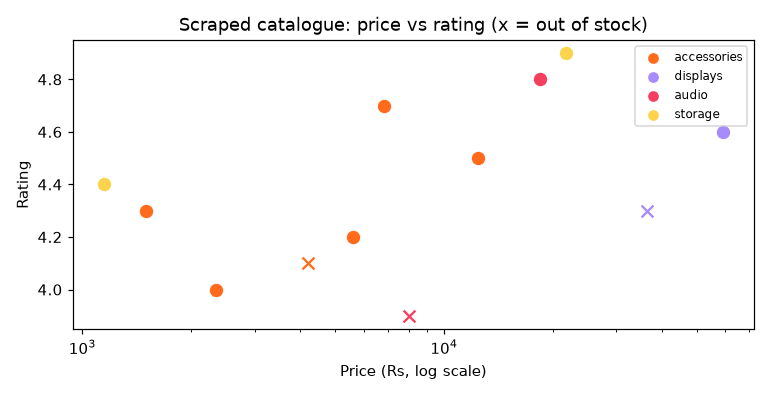

In [6]:
from IPython.display import Image, display
display(Image(filename='session-08_problem_catalogue_scraper.png'))  # chart saved by the cell above

## Example: `session-08_project_job_monitor.py`

In [7]:
"""
Session 8 · Mini project: a job-vacancy monitor with change detection
---------------------------------------------------------------------
Every day a graduate checks a careers page for new jobs. This tool automates it:
  1. scrape the jobs page (title, company, city, posted date, job id),
  2. keep only jobs matching keywords and a city,
  3. compare with the previous run's snapshot (jobs_snapshot.json),
  4. report NEW and REMOVED vacancies, then save the new snapshot.
The demo runs the monitor twice; between the runs the practice site
publishes two more vacancies, just like a real site would over a day.
Run:  python session-08_project_job_monitor.py
"""
import json
import os
from datetime import datetime

import requests
from bs4 import BeautifulSoup
import demo_shop_site as site

SNAPSHOT = "jobs_snapshot.json"
KEYWORDS = ["data", "python", "machine learning", "lab engineer"]
CITY = "Karachi"

def scrape_jobs(base):
    """Return a list of job dicts from the /jobs page."""
    html = requests.get(base + "/jobs", headers={"User-Agent": "DiplomaAI-StudentBot/1.0"}, timeout=10).text
    soup = BeautifulSoup(html, "html.parser")
    jobs = []
    for li in soup.select("ul#jobs li.job"):
        jobs.append({
            "id": li["id"],
            "title": li.h3.get_text(strip=True),
            "company": li.select_one(".company").text,
            "city": li.select_one(".city").text,
            "posted": li.time["datetime"],
        })
    return jobs

def matches(job):
    title = job["title"].lower()
    return job["city"] == CITY and any(k in title for k in KEYWORDS)

def load_snapshot():
    try:
        with open(SNAPSHOT, encoding="utf-8") as f:
            return {j["id"]: j for j in json.load(f)["jobs"]}
    except (FileNotFoundError, json.JSONDecodeError, KeyError):
        return {}

def save_snapshot(jobs, when):
    with open(SNAPSHOT, "w", encoding="utf-8") as f:
        json.dump({"checked_at": when, "jobs": jobs}, f, indent=2)

def run_monitor(base, when):
    print(f"--- check at {when} ---")
    all_jobs = scrape_jobs(base)
    relevant = [j for j in all_jobs if matches(j)]
    old = load_snapshot()
    new_ids = {j["id"] for j in relevant} - set(old)
    gone_ids = set(old) - {j["id"] for j in relevant}
    print(f"page lists {len(all_jobs)} jobs, {len(relevant)} match {KEYWORDS} in {CITY}")
    if not old:
        print("first run: saving a baseline snapshot")
    for j in relevant:
        if j["id"] in new_ids and old:
            print(f"  NEW   {j['id']} {j['title']} @ {j['company']} (posted {j['posted']})")
    for jid in sorted(gone_ids):
        print(f"  GONE  {jid} {old[jid]['title']}")
    if old and not new_ids and not gone_ids:
        print("  no changes")
    save_snapshot(relevant, when)
    return relevant

if os.path.exists(SNAPSHOT):
    os.remove(SNAPSHOT)                       # start fresh for a reproducible demo
site.reset_jobs()
BASE = site.start_site()

first = run_monitor(BASE, "2026-10-22 09:00")
for j in first:
    print(f"  baseline {j['id']} {j['title']}")
site.add_jobs(2)                              # the site publishes two more vacancies
second = run_monitor(BASE, "2026-10-24 09:00")
third = run_monitor(BASE, "2026-10-25 09:00")

print("\nSnapshot file now holds:", [j["id"] for j in json.load(open(SNAPSHOT, encoding="utf-8"))["jobs"]])
os.remove(SNAPSHOT)

--- check at 2026-10-22 09:00 ---
page lists 3 jobs, 2 match ['data', 'python', 'machine learning', 'lab engineer'] in Karachi
first run: saving a baseline snapshot
  baseline J101 Junior Data Analyst
  baseline J102 Python Developer (Flask)
--- check at 2026-10-24 09:00 ---
page lists 5 jobs, 4 match ['data', 'python', 'machine learning', 'lab engineer'] in Karachi
  NEW   J104 Lab Engineer (Computer Science) @ City University (posted 2026-10-23)
  NEW   J105 Data Entry Operator @ Port Logistics (posted 2026-10-24)
--- check at 2026-10-25 09:00 ---
page lists 5 jobs, 4 match ['data', 'python', 'machine learning', 'lab engineer'] in Karachi
  no changes

Snapshot file now holds: ['J101', 'J102', 'J104', 'J105']
